Code pipeline:
- read video from same folder
- convert video to grayscale
- take average grayscale value of each frame
- plot value against time
- extract pulse rate using f = 1/T

In [2]:
#import libraries 
import numpy as np 
import matplotlib.pyplot as plt 


In [6]:
import cv2
print(cv2.__version__)

5.1.0


In [13]:
from videoreader import VideoReader #imports video reading extension


In [14]:
#select video path 
video = 'data/video_of_finger_compressed.mp4'
cap = cv2.VideoCapture(video)
vr = VideoReader('data/video_of_finger_compressed.mp4')
print(vr)  # prints video_file_name, number of frames, frame rate and frame size

data/video_of_finger_compressed.mp4 with 1852 frames of size (1920, 1080, 3) at 29.97 fps


In [15]:
print(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fr1 = vr[1] #testing format of array

1852.0


In [16]:
frames = []
while cap.isOpened():
    ret, frame = cap.read() #reads video frame by frame
    if not ret:
        break  # stops video

  
    grayscale = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) # converts video to grayscale

    
    avg = np.mean(grayscale) # finds average intensity per frame
    frames.append(avg) # puts intensities into an array

cap.release()

print(frames)




[np.float64(69.64183497299383), np.float64(69.40195987654322), np.float64(67.92441936728395), np.float64(66.24676408179012), np.float64(65.01118007330247), np.float64(64.36900704089506), np.float64(63.758940489969135), np.float64(63.75441936728395), np.float64(63.99348042052469), np.float64(64.22652391975309), np.float64(64.57165268132717), np.float64(64.9519208140432), np.float64(65.09564477237655), np.float64(65.22298128858024), np.float64(65.3100641396605), np.float64(65.46053867669752), np.float64(65.67822386188271), np.float64(66.13220775462963), np.float64(66.54454475308641), np.float64(67.05955777391975), np.float64(67.74042004243827), np.float64(68.2906814236111), np.float64(68.90859953703703), np.float64(69.18169849537037), np.float64(69.53273582175926), np.float64(69.79687934027778), np.float64(69.69364728009259), np.float64(68.22210841049383), np.float64(66.23912856867284), np.float64(65.30197916666667), np.float64(64.58414641203704), np.float64(64.1772617669753), np.float64

In [18]:
cap = cv2.VideoCapture(video)

fr = cap.get(cv2.CAP_PROP_FRAME_COUNT) # get number of frames
np.int32(fr) # change frames to integer values
frar = np.arange(1,fr+1) # make an array from 1 - frame number
print(frar)


[1.000e+00 2.000e+00 3.000e+00 ... 1.850e+03 1.851e+03 1.852e+03]


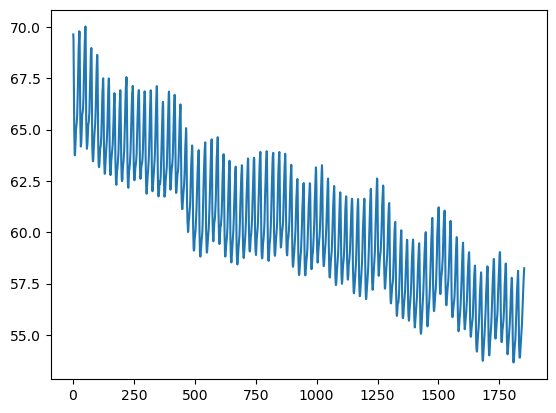

In [19]:
plt.plot(frar, frames) # plot intensity against frame number

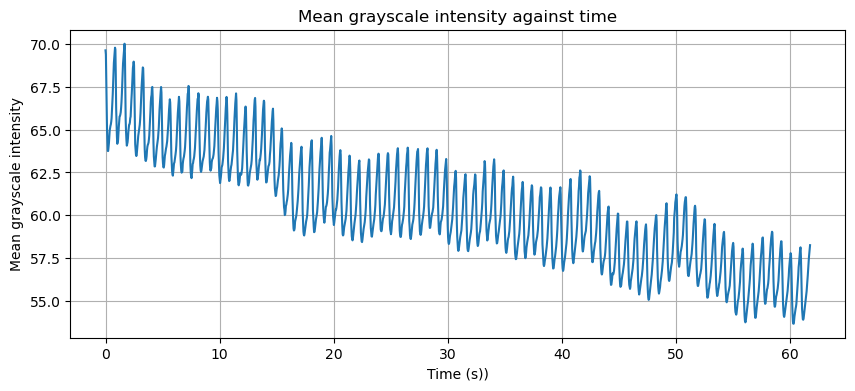

In [ ]:
# Reopen the video again as it was released earlier
cap = cv2.VideoCapture(video)

# Obtain the sampling frequency (number of frames per second)
fs = cap.get(cv2.CAP_PROP_FPS) # Sampling frequency
N = len(frames) # Obtain the total number of frames by counting the grayscale values 

# Convert frame numbers into their corresponding times in seconds
# by dividing them by the number of frames recorded per second
time = np.arange(N) / fs # Time array in seconds



# Plot the mean grayscale intensity against time 
plt.figure(figsize=(10,4))
plt.plot(time, frames)
plt.xlabel("Time (s))")
plt.ylabel("Mean grayscale intensity")
plt.title("Mean grayscale intensity against time")
plt.grid()
plt.show()

cap.release() # Close the video capture object

In [32]:
# Calculate FFT of grayscale signal
signal_fft = np.fft.fft(frames)

#frequency array
frequencies = np.fft.fftfreq(N, 1/fs)
print(frequencies)


[ 0.          0.01618252  0.03236504 ... -0.04854756 -0.03236504
 -0.01618252]


In [33]:
# Calculate the power spectrum
signal_power = np.abs(signal_fft)**2 / N

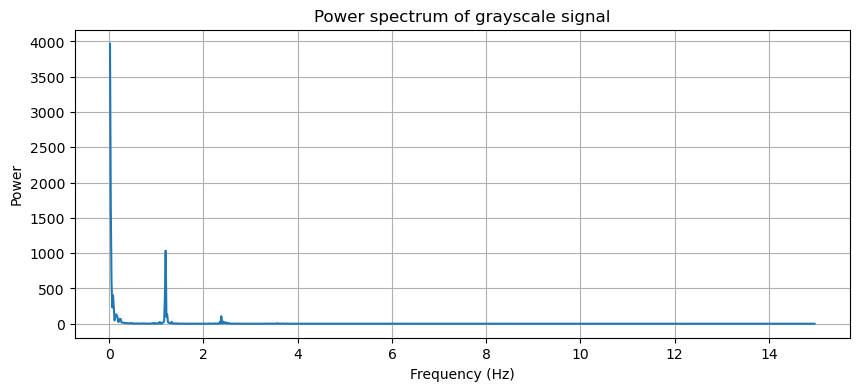

In [35]:
# Select positive frequencies 
mask = (frequencies > 0)

# Plot power spectrum
plt.figure(figsize=(10,4))
plt.plot(frequencies[mask], signal_power[mask])
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power")
plt.title("Power spectrum of grayscale signal")
plt.grid()
plt.show()